In [1]:
import sys
import pandas as pd
import numpy as np
   
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.12.9
pandas: 3.1.1
numpy: 2.5.4


In [ ]:
fake = pd.read_csv("data/Fake.csv")
real = pd.read_csv("data/True.csv")

print("Fake shape:", fake.shape)
print("Real shape:", real.shape)
print("Columns:", list(fake.columns))

fake.head()

Fake shape: (23481, 4)
Real shape: (21417, 4)
Columns: ['title', 'text', 'subject', 'date']


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [3]:
   print("Missing values in Fake:")
   print(fake.isnull().sum())
   print("\nMissing values in Real:")
   print(real.isnull().sum())

   print("\nDuplicate rows in Fake:", fake.duplicated().sum())
   print("Duplicate rows in Real:", real.duplicated().sum())

   print("\nEmpty text in Fake:", (fake["text"].str.strip() == "").sum())
   print("Empty text in Real:", (real["text"].str.strip() == "").sum())

Missing values in Fake:
title      0
text       0
subject    0
date       0
dtype: int64

Missing values in Real:
title      0
text       0
subject    0
date       0
dtype: int64

Duplicate rows in Fake: 3
Duplicate rows in Real: 206

Empty text in Fake: 630
Empty text in Real: 1


In [4]:
   print("Fake subjects:")
   print(fake["subject"].value_counts())
   print("\nReal subjects:")
   print(real["subject"].value_counts())

Fake subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [5]:
   fake = fake.drop_duplicates().copy()
   real = real.drop_duplicates().copy()

   fake = fake[fake["text"].str.strip() != ""].copy()
   real = real[real["text"].str.strip() != ""].copy()

   fake["label"] = 0   # 0 = fake
   real["label"] = 1   # 1 = real

   print("Fake after cleaning:", fake.shape)
   print("Real after cleaning:", real.shape)

Fake after cleaning: (22848, 5)
Real after cleaning: (21210, 5)


In [6]:
   df = pd.concat([fake, real], ignore_index=True)
   df["content"] = df["title"] + " " + df["text"]
   df = df[["content", "label"]]
   df = df.sample(frac=1, random_state=42).reset_index(drop=True)

   print("Combined shape:", df.shape)
   print(df["label"].value_counts())
   df.head()

Combined shape: (44058, 2)
label
0    22848
1    21210
Name: count, dtype: int64


,content,label
0,JUDGE JEANINE PIRRO DECLARES WAR On Hillary…Le...,0
1,WATCH: Giuliani’s BIG LIE At Trump Rally Is J...,0
2,Republican House Speaker Ryan backs Trump afte...,1
3,Wikileaks: NSA Spied on UN Secretary-General a...,0
4,Freeing of hostages in Pakistan a 'positive si...,1


In [7]:
   df.to_csv("data/cleaned_news.csv", index=False)

In [8]:
   import re
   import nltk
   from nltk.corpus import stopwords
   from nltk.stem import WordNetLemmatizer

   nltk.download("stopwords")
   nltk.download("wordnet")
   print("nltk:", nltk.__version__)

   stop_words = set(stopwords.words("english"))
   lemmatizer = WordNetLemmatizer()

   def preprocess(text):
       text = text.lower()
       text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove links
       text = re.sub(r"[^a-z\s]", " ", text)           # keep letters only
       tokens = text.split()
       tokens = [
           lemmatizer.lemmatize(t)
           for t in tokens
           if t not in stop_words and len(t) > 2
       ]
       return " ".join(tokens)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AreebaGhaffar\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\AreebaGhaffar\AppData\Roaming\nltk_data...


nltk: 3.10.4


In [9]:
   sample = df["content"].iloc[0]
   print("BEFORE:\n", sample[:300])
   print("\nAFTER:\n", preprocess(sample)[:300])

BEFORE:
 JUDGE JEANINE PIRRO DECLARES WAR On Hillary…Leaked E-Mails Prove The Election Was Rigged [Video] Judge Jeanine Pirro rips into  Crooked  Hillary for her collusion in rigging the election process so she would come out on top of Bernie Sanders: 

AFTER:
 judge jeanine pirro declares war hillary leaked mail prove election rigged video judge jeanine pirro rip crooked hillary collusion rigging election process would come top bernie sander


In [10]:
   df["clean_content"] = df["content"].apply(preprocess)

   # drop rows that became empty after cleaning
   df = df[df["clean_content"].str.strip() != ""].reset_index(drop=True)

   print("Shape after preprocessing:", df.shape)
   print(df["label"].value_counts())
   df[["clean_content", "label"]].head()

Shape after preprocessing: (44049, 3)
label
0    22839
1    21210
Name: count, dtype: int64


,clean_content,label
0,judge jeanine pirro declares war hillary leake...,0
1,watch giuliani big lie trump rally jaw droppin...,0
2,republican house speaker ryan back trump long ...,1
3,wikileaks nsa spied secretary general world le...,0
4,freeing hostage pakistan positive sign general...,1


In [11]:
   df.to_csv("data/preprocessed_news.csv", index=False)

In [12]:
   import sklearn
   from sklearn.model_selection import train_test_split

   print("scikit-learn:", sklearn.__version__)

   X = df["clean_content"]
   y = df["label"]

   X_train, X_test, y_train, y_test = train_test_split(
       X, y, test_size=0.2, random_state=42, stratify=y
   )

   print("Train size:", X_train.shape[0])
   print("Test size:", X_test.shape[0])
   print("\nTrain labels:\n", y_train.value_counts(normalize=True))
   print("\nTest labels:\n", y_test.value_counts(normalize=True))

scikit-learn: 1.9.1
Train size: 35239
Test size: 8810

Train labels:
 label
0    0.518488
1    0.481512
Name: proportion, dtype: float64

Test labels:
 label
0    0.518502
1    0.481498
Name: proportion, dtype: float64


In [13]:
   from sklearn.feature_extraction.text import TfidfVectorizer

   vectorizer = TfidfVectorizer(
       max_features=20000,
       ngram_range=(1, 2),
       min_df=5
   )

   X_train_tfidf = vectorizer.fit_transform(X_train)   # learn vocabulary from train only
   X_test_tfidf = vectorizer.transform(X_test)         # only apply to test

   print("Train matrix shape:", X_train_tfidf.shape)
   print("Test matrix shape:", X_test_tfidf.shape)
   print("Sample features:", vectorizer.get_feature_names_out()[:20])

Train matrix shape: (35239, 20000)
Test matrix shape: (8810, 20000)
Sample features: ['aaron' 'abadi' 'abadi said' 'abandon' 'abandoned' 'abandoning' 'abbas'
 'abbott' 'abc' 'abc news' 'abc week' 'abd' 'abdel' 'abdel fattah'
 'abducted' 'abduction' 'abdul' 'abdullah' 'abdullah saleh' 'abe']


In [14]:
   from sklearn.linear_model import LogisticRegression
   from sklearn.metrics import accuracy_score, f1_score, classification_report

   lr = LogisticRegression(max_iter=1000, random_state=42)
   lr.fit(X_train_tfidf, y_train)
   lr_pred = lr.predict(X_test_tfidf)

   print("Logistic Regression")
   print("Accuracy:", round(accuracy_score(y_test, lr_pred), 4))
   print("F1-score:", round(f1_score(y_test, lr_pred), 4))
   print("\n", classification_report(y_test, lr_pred, target_names=["Fake", "Real"]))

Logistic Regression
Accuracy: 0.9904
F1-score: 0.99

               precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4568
        Real       0.99      0.99      0.99      4242

    accuracy                           0.99      8810
   macro avg       0.99      0.99      0.99      8810
weighted avg       0.99      0.99      0.99      8810



In [15]:
   from sklearn.svm import LinearSVC

   svm = LinearSVC(random_state=42)
   svm.fit(X_train_tfidf, y_train)
   svm_pred = svm.predict(X_test_tfidf)

   print("Linear SVM")
   print("Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
   print("F1-score:", round(f1_score(y_test, svm_pred), 4))
   print("\n", classification_report(y_test, svm_pred, target_names=["Fake", "Real"]))

Linear SVM
Accuracy: 0.9964
F1-score: 0.9962

               precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4568
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8810
   macro avg       1.00      1.00      1.00      8810
weighted avg       1.00      1.00      1.00      8810



In [17]:
   results = pd.DataFrame({
       "Model": ["Logistic Regression", "Linear SVM"],
       "Accuracy": [accuracy_score(y_test, lr_pred), accuracy_score(y_test, svm_pred)],
       "F1-score": [f1_score(y_test, lr_pred), f1_score(y_test, svm_pred)],
   }).round(4)

   results

,Model,Accuracy,F1-score
0,Logistic Regression,0.9904,0.9900
1,Linear SVM,0.9964,0.9962


matplotlib: 3.11.2


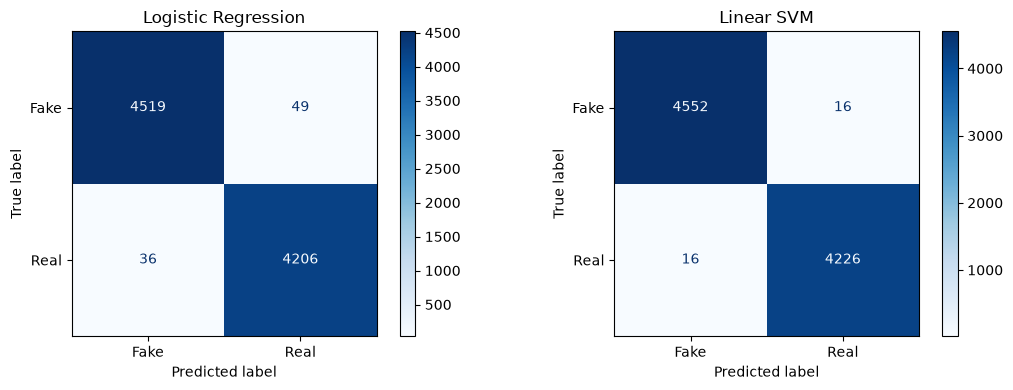

In [18]:
   import matplotlib
   import matplotlib.pyplot as plt
   from sklearn.metrics import ConfusionMatrixDisplay

   print("matplotlib:", matplotlib.__version__)

   fig, axes = plt.subplots(1, 2, figsize=(11, 4))

   ConfusionMatrixDisplay.from_predictions(
       y_test, lr_pred, display_labels=["Fake", "Real"], ax=axes[0], cmap="Blues"
   )
   axes[0].set_title("Logistic Regression")

   ConfusionMatrixDisplay.from_predictions(
       y_test, svm_pred, display_labels=["Fake", "Real"], ax=axes[1], cmap="Blues"
   )
   axes[1].set_title("Linear SVM")

   plt.tight_layout()
   plt.savefig("images/confusion_matrices.png", dpi=150)
   plt.show()